# Case A walkthrough: ANN for late-shipment prediction
**K. Scott Dickenson | University of Denver**

This notebook walks through the Case A neural network reported in *Mapping before modeling*. It trains a feedforward artificial neural network (multilayer perceptron) to predict late shipments on the course example dataset and compares it with logistic regression, random forest, gradient boosting, and a majority-class baseline.

**Data.** Kaggle *Customer Analytics* (prachi13), e-commerce shipping records. In this dataset `Reached.on.Time_Y.N = 1` means the shipment was **late**. Set `DATA_PATH` to your copy. The loader detects comma or semicolon separators automatically.

## 1. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, precision_score, recall_score, roc_curve
from sklearn.inspection import permutation_importance
import warnings; warnings.filterwarnings("ignore")

DATA_PATH = "../data/Train.csv"   # Kaggle file; see data/README.md
MAX_ID = 8999                     # labeled subset used in the paper; set to 0 for all records
SEED = 42

## 2. Load and prepare the data

In [2]:
df = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding="utf-8-sig")
df = df.drop_duplicates(subset="ID")
if MAX_ID:
    df = df[df["ID"] <= MAX_ID]
print(df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head()

(8999, 12) | missing values: 0


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [3]:
y = df["Reached.on.Time_Y.N"].astype(int)          # 1 = late
X = df.drop(columns=["ID", "Reached.on.Time_Y.N", "Gender"])  # Gender has no operational meaning
cat = ["Warehouse_block", "Mode_of_Shipment", "Product_importance"]
num = [c for c in X.columns if c not in cat]
print(f"Late-shipment rate: {y.mean():.1%}")

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("Train:", len(Xtr), "| Test:", len(Xte))

pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                         ("num", StandardScaler(), num)])
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

Late-shipment rate: 63.6%
Train: 6749 | Test: 2250


## 3. Tune the ANN (multilayer perceptron)
ReLU activations, Adam optimizer, and early stopping. Five-fold cross-validation searches hidden-layer sizes and L2 regularization strength (`alpha`), optimizing AUC.

In [4]:
mlp = Pipeline([("pre", pre), ("m", MLPClassifier(max_iter=600, early_stopping=True, validation_fraction=0.15,
                                                   n_iter_no_change=25, random_state=SEED))])
grid = GridSearchCV(mlp, {"m__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
                          "m__alpha": [1e-4, 1e-3, 1e-2]},
                    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(Xtr, ytr)
print("Best parameters:", grid.best_params_)
print(f"Best CV AUC: {grid.best_score_:.3f}")

Best parameters: {'m__alpha': 0.01, 'm__hidden_layer_sizes': (64, 32)}
Best CV AUC: 0.769


## 4. Train comparison models and evaluate on the test set

In [5]:
models = {
    "Majority-class baseline": Pipeline([("pre", pre), ("m", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("pre", pre), ("m", LogisticRegression(max_iter=2000))]),
    "Random forest": Pipeline([("pre", pre), ("m", RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                                                          random_state=SEED, n_jobs=-1))]),
    "Gradient boosting": Pipeline([("pre", pre), ("m", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                                                                      max_iter=300, random_state=SEED))]),
    "ANN (MLP)": grid.best_estimator_,
}
rows, rocs = [], {}
for name, m in models.items():
    if name != "ANN (MLP)":
        m.fit(Xtr, ytr)
    cv_auc = 0.5 if name.startswith("Majority") else cross_val_score(m, Xtr, ytr, cv=cv, scoring="roc_auc").mean()
    p = m.predict_proba(Xte)[:, 1]; yh = (p >= 0.5).astype(int)
    rows.append({"Model": name, "CV AUC": cv_auc, "Test AUC": roc_auc_score(yte, p),
                 "Accuracy": accuracy_score(yte, yh), "Precision": precision_score(yte, yh, zero_division=0),
                 "Recall": recall_score(yte, yh), "F1": f1_score(yte, yh)})
    if not name.startswith("Majority"):
        rocs[name] = roc_curve(yte, p)
results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,CV AUC,Test AUC,Accuracy,Precision,Recall,F1
Model,,,,,,
Majority-class baseline,0.500,0.500,0.636,0.636,1.000,0.777
Logistic regression,0.757,0.760,0.676,0.748,0.738,0.743
Random forest,0.782,0.772,0.689,0.836,0.636,0.723
Gradient boosting,0.780,0.760,0.686,0.843,0.622,0.715
ANN (MLP),0.769,0.767,0.685,0.784,0.697,0.738


## 5. ROC curves (Figure 1)

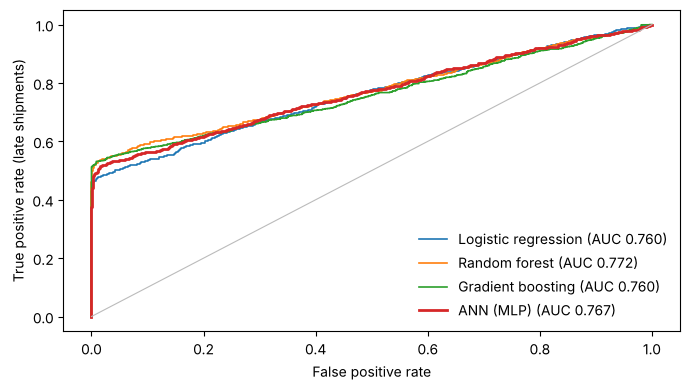

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, (f, t, _) in rocs.items():
    ax.plot(f, t, lw=2 if name == "ANN (MLP)" else 1.2, label=f"{name} (AUC {results.loc[name, 'Test AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="#bbbbbb", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (late shipments)")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

## 6. Permutation importance for the ANN (Figure 2)

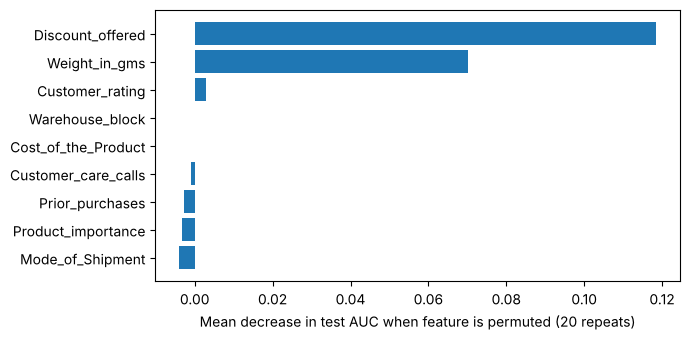

Discount_offered       0.1185
Weight_in_gms          0.0701
Customer_rating        0.0028
Warehouse_block        0.0001
Cost_of_the_Product    0.0001
Customer_care_calls   -0.0010
Prior_purchases       -0.0026
Product_importance    -0.0034
Mode_of_Shipment      -0.0040
dtype: float64

In [7]:
pi = permutation_importance(models["ANN (MLP)"], Xte, yte, scoring="roc_auc", n_repeats=20, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(imp.index, imp.values)
ax.set_xlabel("Mean decrease in test AUC when feature is permuted (20 repeats)")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4)

## 7. Discount diagnostic

In [8]:
high = df["Discount_offered"] > 10
print(f"Share of shipments with discount > 10: {high.mean():.1%}")
print(f"Late rate, discount > 10:  {y[high].mean():.1%}")
print(f"Late rate, discount <= 10: {y[~high].mean():.1%}")

Share of shipments with discount > 10: 29.4%
Late rate, discount > 10:  100.0%
Late rate, discount <= 10: 48.4%


## 8. Interpretation
The ANN improves on the majority-class baseline and performs about as well as the tree ensembles, with the best balance of precision and recall among the trained models. Nearly all predictive signal comes from discount offered and product weight, and every shipment with a discount above 10 is late, which suggests a policy artifact or synthetic data pattern. On small tabular data dominated by a few strong variables, ANNs tend to match rather than beat simpler models. Note that the gradient boosting model uses fixed settings while the ANN was tuned.